In [1]:
# Step 1: Import required libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Face image shape (height, width, channels): (531, 413, 3)


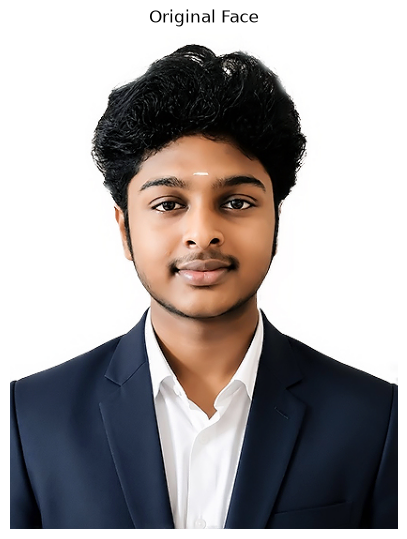

In [2]:
# Step 2: Load and display the face image
faceImage = cv2.imread('ram.jpeg')

if faceImage is None:
    raise FileNotFoundError("Place ram.jpeg in the same folder as this notebook.")

print("Face image shape (height, width, channels):", faceImage.shape)

plt.figure(figsize=(5, 7))
plt.imshow(cv2.cvtColor(faceImage, cv2.COLOR_BGR2RGB))
plt.title("Original Face")
plt.axis('off')
plt.show()

Sunglasses image shape (height, width, channels): (338, 507, 3)


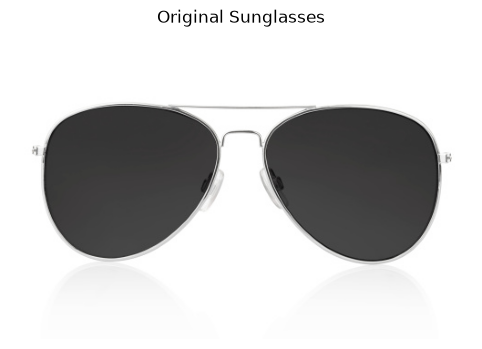

In [4]:
# Step 3: Load and display the sunglasses image
glassImage = cv2.imread('glass.jpg', cv2.IMREAD_COLOR)

if glassImage is None:
    raise FileNotFoundError("Place glass.jpg in the same folder as this notebook.")

print("Sunglasses image shape (height, width, channels):", glassImage.shape)

plt.figure(figsize=(7, 4))
plt.imshow(cv2.cvtColor(glassImage, cv2.COLOR_BGR2RGB))
plt.title("Original Sunglasses")
plt.axis('off')
plt.show()

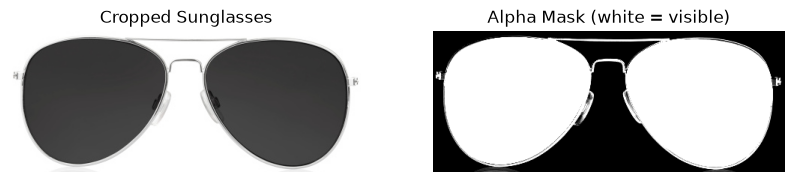

In [5]:
# Step 4: Crop the sunglasses and remove the white background using a soft alpha mask
# Crop out the large white margins and the reflection below the glasses.
glassCrop = glassImage[72:260, 20:490]

# White background pixels become transparent.
# A soft transition helps preserve the light silver frame edges.
minChannel = glassCrop.min(axis=2).astype(np.float32)
maxChannel = glassCrop.max(axis=2).astype(np.float32)

glassAlpha = np.clip((248 - minChannel) / 38.0, 0.0, 1.0)
whiteBackground = (minChannel > 246) & ((maxChannel - minChannel) < 12)
glassAlpha[whiteBackground] = 0.0

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(glassCrop, cv2.COLOR_BGR2RGB))
plt.title("Cropped Sunglasses")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(glassAlpha, cmap='gray', vmin=0, vmax=1)
plt.title("Alpha Mask (white = visible)")
plt.axis('off')
plt.show()

In [12]:
# Step 5: Resize the sunglasses to fit the eyes more naturally
# Smaller width helps the glasses fit within the eye/temple area.
# Increase or decrease targetWidth slightly if needed.
targetWidth = 160
targetHeight = int(glassCrop.shape[0] * targetWidth / glassCrop.shape[1])

glassBGR = cv2.resize(glassCrop, (targetWidth, targetHeight), interpolation=cv2.INTER_AREA)
glassAlpha = cv2.resize(glassAlpha, (targetWidth, targetHeight), interpolation=cv2.INTER_AREA)

print("Resized sunglasses (height, width):", glassBGR.shape[:2])


Resized sunglasses (height, width): (64, 160)


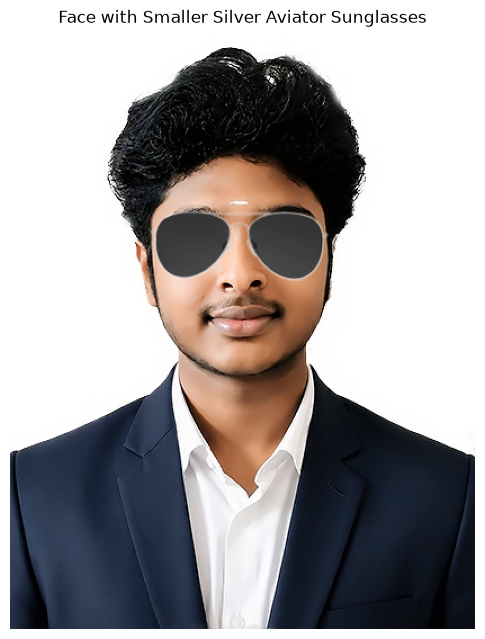

In [20]:
# Step 6: Place the smaller sunglasses over the eyes and blend the pixels
# x1 moves the glasses left/right; y1 moves them up/down.
# These values are adjusted for ram.jpeg and the smaller 165-pixel width.
x1, y1 = 124, 158

h, w = glassBGR.shape[:2]
x2, y2 = x1 + w, y1 + h

if x1 < 0 or y1 < 0 or x2 > faceImage.shape[1] or y2 > faceImage.shape[0]:
    raise ValueError("Sunglasses placement is outside the face image. Adjust x1/y1 or targetWidth.")

faceWithGlasses = faceImage.copy()
roi = faceWithGlasses[y1:y2, x1:x2].astype(np.float32)
alpha = glassAlpha[:, :, None].astype(np.float32)

blended = roi * (1 - alpha) + glassBGR.astype(np.float32) * alpha
faceWithGlasses[y1:y2, x1:x2] = np.clip(blended, 0, 255).astype(np.uint8)

plt.figure(figsize=(6, 8))
plt.imshow(cv2.cvtColor(faceWithGlasses, cv2.COLOR_BGR2RGB))
plt.title("Face with Smaller Silver Aviator Sunglasses")
plt.axis('off')
plt.show()


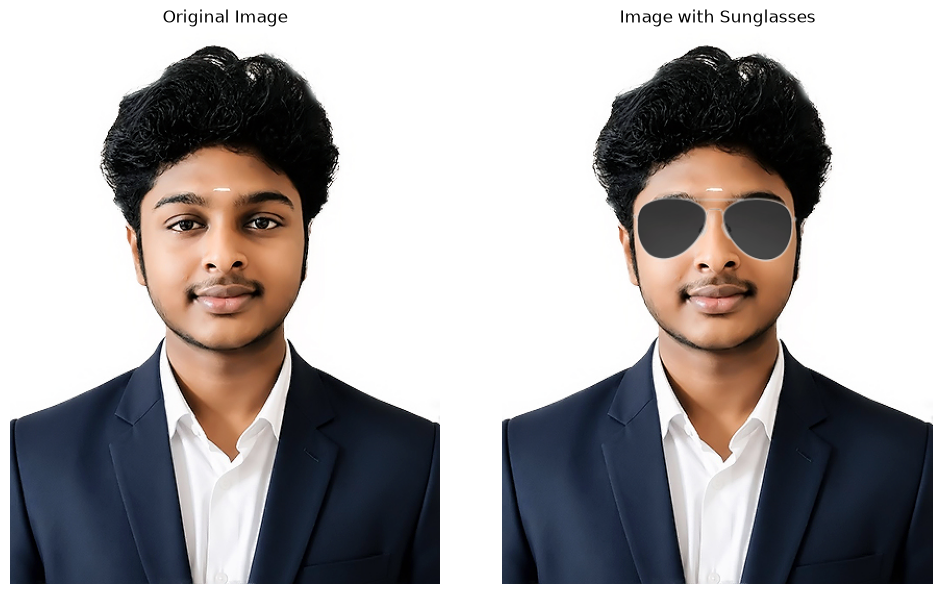

In [21]:

# Step 7: Compare the original and transformed images

plt.figure(figsize=(10, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(faceImage, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(faceWithGlasses, cv2.COLOR_BGR2RGB))
plt.title("Image with Sunglasses")
plt.axis("off")

plt.tight_layout()
plt.show()


In [9]:
# Step 8: Save the final output image
outputPath = 'ram_with_glass.jpg'
cv2.imwrite(outputPath, faceWithGlasses)
print("Saved output as:", outputPath)

Saved output as: ram_with_glass.jpg
